In [18]:
# Imports
import pandas as pd
import numpy as np
import sqlite3
import datetime
# import math
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix

In [2]:
gcm_data_path = 'MaxMustermann_glucose_20-10-2026.csv'
diary_data_path = 'glpred.db'

#### Read and preprocess user Continuous Glucose Monitoring (CGM) device data
- The data is from https://www2.libreview.com/glucosereports
- The file is of following format: MaxMustermann_glucose_20-10-2026.csv
- Serves the purpose of generating labels y

In [3]:
def load_gcm_data(
    path: str,
) -> pd.DataFrame:
    df = pd.read_csv(path, header=1)

    # Drop rows empty in both columns and ensure an independent copy of the dataframe
    filtered_df = df.dropna(subset=['Historic Glucose mg/dL', 'Scan Glucose mg/dL'], how='all').copy()
    
    # Combine the columns into a new unified series
    filtered_df['glucose'] = filtered_df['Scan Glucose mg/dL'].combine_first(filtered_df['Historic Glucose mg/dL'])
    
    # Retain only the timestamp and the new combined glucose column
    filtered_df = filtered_df[['Device Timestamp', 'glucose']].rename(columns={'Device Timestamp': 'timestamp'})
    
    # Convert timestamp to datetime
    filtered_df['timestamp'] = pd.to_datetime(filtered_df['timestamp'], dayfirst=True)
    
    # Resample to a continuous 1-minute grid and interpolate missing gaps immediately
    cgm_grid = (
        filtered_df.set_index('timestamp')
        .resample('1min')
        .mean()
        .interpolate(method='linear')
        .reset_index()
    )

    return cgm_grid

print(load_gcm_data(gcm_data_path).iloc[195:202])

              timestamp  glucose
195 2025-09-27 03:08:00    148.2
196 2025-09-27 03:09:00    147.0
197 2025-09-27 03:10:00    145.8
198 2025-09-27 03:11:00    144.6
199 2025-09-27 03:12:00    143.4
200 2025-09-27 03:13:00    142.2
201 2025-09-27 03:14:00    141.0


##### Optional: Verify functionality

In [4]:
df = pd.read_csv(gcm_data_path, header=1)

# Drop rows empty in both columns and ensure an independent copy of the dataframe
filtered_df = df.dropna(subset=['Historic Glucose mg/dL', 'Scan Glucose mg/dL'], how='all').copy()

# Combine the columns into a new unified series
filtered_df['glucose'] = filtered_df['Scan Glucose mg/dL'].combine_first(filtered_df['Historic Glucose mg/dL'])

# Retain only the timestamp and the new combined glucose column
filtered_df = filtered_df[['Device Timestamp', 'glucose']].rename(columns={'Device Timestamp': 'timestamp'})

# Convert timestamp to datetime
filtered_df['timestamp'] = pd.to_datetime(filtered_df['timestamp'], dayfirst=True)

# Resample to a continuous 1-minute grid and interpolate missing gaps
cgm_grid = (
    filtered_df.set_index('timestamp')
    .resample('1min')
    .mean()
    .interpolate(method='linear')
    .reset_index()
)

print("Updated Columns:", filtered_df.columns)
print("Filtered shape:", filtered_df.shape)
print(filtered_df.sort_values(by='timestamp').reset_index(drop=True).iloc[195:202])
print("CGM grid shape:", cgm_grid.shape)
print(cgm_grid.iloc[195:202])


Updated Columns: Index(['timestamp', 'glucose'], dtype='object')
Filtered shape: (280142, 2)
              timestamp  glucose
195 2025-09-27 02:59:00    159.0
196 2025-09-27 03:04:00    153.0
197 2025-09-27 03:09:00    147.0
198 2025-09-27 03:14:00    141.0
199 2025-09-27 03:15:00    136.0
200 2025-09-27 03:16:00    135.0
201 2025-09-27 03:18:00    134.0
CGM grid shape: (559458, 2)
              timestamp  glucose
195 2025-09-27 03:08:00    148.2
196 2025-09-27 03:09:00    147.0
197 2025-09-27 03:10:00    145.8
198 2025-09-27 03:11:00    144.6
199 2025-09-27 03:12:00    143.4
200 2025-09-27 03:13:00    142.2
201 2025-09-27 03:14:00    141.0


##### Optional: Find out the time span this data ist from 

In [5]:
# Compute the time span directly on a temporary conversion without altering filtered_df
start_time = pd.to_datetime(filtered_df['timestamp'], format='%d-%m-%Y %H:%M').min()
end_time = pd.to_datetime(filtered_df['timestamp'], format='%d-%m-%Y %H:%M').max()

print(f"Dataset time span: {start_time} through {end_time}")

Dataset time span: 2025-09-26 23:53:00 through 2026-10-20 12:10:00


#### Import app SQLite database from device (X_data)
- This data is generated via human inputs into an android app, from which it is fetched when the device is connected to the PC
- (currently running on madeup data)

In [6]:
def load_diary_data(
    path: str,
) -> pd.DataFrame:
    con = sqlite3.connect(path)
    diary_df = pd.read_sql_query("SELECT * from diary_table", con)
    con.close()
    
    diary_df['timestamp'] = pd.to_datetime(diary_df['date'] + " " + diary_df['time'], dayfirst=True)
    diary_df = diary_df[['timestamp', 'glucose', 'carbs', 'bolus', 'basis']]
    diary_df = diary_df.sort_values(["timestamp"]).reset_index(drop=True)
    return diary_df

print(load_diary_data(diary_data_path))
print(load_diary_data(diary_data_path).dtypes)

            timestamp  glucose  carbs  bolus  basis
0 2026-10-18 13:45:00      130    6.0      9      0
1 2026-10-19 07:33:00      146    8.0     16     12
2 2026-10-19 12:40:00       80   10.0     10     12
3 2026-10-19 18:22:00      187    4.7     13     12
timestamp    datetime64[ns]
glucose               int64
carbs               float64
bolus                 int64
basis                 int64
dtype: object


#### Generate data labels (y_data)
- for SQLite database data from device
- applicable for bloodsugar values after 3, 4 and 5hours 

In [11]:
def gen_labels(
    df_diary: pd.DataFrame,
    df_cgm: pd.DataFrame,
    hours_passed: int,
) -> pd.DataFrame:

    # Create a working copy of the diary timestamps
    targets = df_diary[['timestamp']].copy()
    
    # Shift the timestamp by the specified prediction horizon
    targets['target_time'] = targets['timestamp'] + pd.Timedelta(hours=hours_passed)
    
    # Merge with the continuous CGM grid on the exact timestamp
    merged = pd.merge(
        targets,
        df_cgm,
        left_on='target_time',
        right_on='timestamp',
        how='left'
    )
    
    column_name = f"glucose_level_{hours_passed}h"
    return pd.DataFrame({column_name: merged['glucose']})

diary_data = load_diary_data(diary_data_path)
gcm_data = load_gcm_data(gcm_data_path)
print(gcm_data)
print(diary_data)
print(gen_labels(diary_data, gcm_data, 3))
print(gen_labels(diary_data, gcm_data, 4))
print(gen_labels(diary_data, gcm_data, 5))

                 timestamp  glucose
0      2025-09-26 23:53:00    302.0
1      2025-09-26 23:54:00    303.5
2      2025-09-26 23:55:00    309.0
3      2025-09-26 23:56:00    312.0
4      2025-09-26 23:57:00    315.0
...                    ...      ...
559453 2026-10-20 12:06:00    188.0
559454 2026-10-20 12:07:00    190.0
559455 2026-10-20 12:08:00    192.0
559456 2026-10-20 12:09:00    193.0
559457 2026-10-20 12:10:00    193.0

[559458 rows x 2 columns]
            timestamp  glucose  carbs  bolus  basis
0 2026-10-18 13:45:00      130    6.0      9      0
1 2026-10-19 07:33:00      146    8.0     16     12
2 2026-10-19 12:40:00       80   10.0     10     12
3 2026-10-19 18:22:00      187    4.7     13     12
   glucose_level_3h
0             151.0
1             129.5
2             173.6
3             271.5
   glucose_level_4h
0             89.00
1            149.75
2            159.80
3            243.00
   glucose_level_5h
0             113.2
1             115.0
2             117.0
3

#### Optional: Prepare Data for Analysis/Visualizations and Machine Learning

In [18]:
X_data = load_diary_data(diary_data_path)
gcm_data = load_gcm_data(gcm_data_path)

# add generated labels
y_data = gen_labels(X_data, gcm_data, 3)
X_data['glucose_3h'] = y_data

print(X_data)

def pp_analysis(
    data: pd.DataFrame,
) -> pd.DataFrame:

    pp_data = data.copy()
    
    # remove date and seperator ':'
    pp_data['timestamp'] = pp_data['timestamp'].dt.strftime('%H:%M')
    pp_data['timestamp'] = pp_data['timestamp'].str.replace(':', '')
    
    # remove leading 0s
    pp_data['timestamp'] = pp_data['timestamp'].str.lstrip('0')
    
    # transform string to int64
    pp_data['timestamp'] = pp_data['timestamp'].astype('int64')
    
    
    # restructure df
    pp_data.rename(columns={'timestamp': 'time'}, inplace=True)

    return pp_data

print(pp_analysis(X_data))
print(pp_analysis(X_data).dtypes)

            timestamp  glucose  carbs  bolus  basis  glucose_3h
0 2026-10-18 13:45:00      130    6.0      9      0       151.0
1 2026-10-19 07:33:00      146    8.0     16     12       129.5
2 2026-10-19 12:40:00       80   10.0     10     12       173.6
3 2026-10-19 18:22:00      187    4.7     13     12       271.5
   time  glucose  carbs  bolus  basis  glucose_3h
0  1345      130    6.0      9      0       151.0
1   733      146    8.0     16     12       129.5
2  1240       80   10.0     10     12       173.6
3  1822      187    4.7     13     12       271.5
time            int64
glucose         int64
carbs         float64
bolus           int64
basis           int64
glucose_3h    float64
dtype: object


#### Optional: Vizualize/Analyze Data

Visualizing iit data.. 


----- iit data head -----
   time  glucose  carbs  bolus  basis  glucose_3h
0  1345      130    6.0      9      0       151.0
1   733      146    8.0     16     12       129.5
2  1240       80   10.0     10     12       173.6
3  1822      187    4.7     13     12       271.5


----- Data info -----
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   time        4 non-null      int64  
 1   glucose     4 non-null      int64  
 2   carbs       4 non-null      float64
 3   bolus       4 non-null      int64  
 4   basis       4 non-null      int64  
 5   glucose_3h  4 non-null      float64
dtypes: float64(2), int64(4)
memory usage: 320.0 bytes
None


----- Data Description -----
              time     glucose      carbs      bolus  basis  glucose_3h
count     4.000000    4.000000   4.000000   4.000000    4.0     4.00000
mean   1285

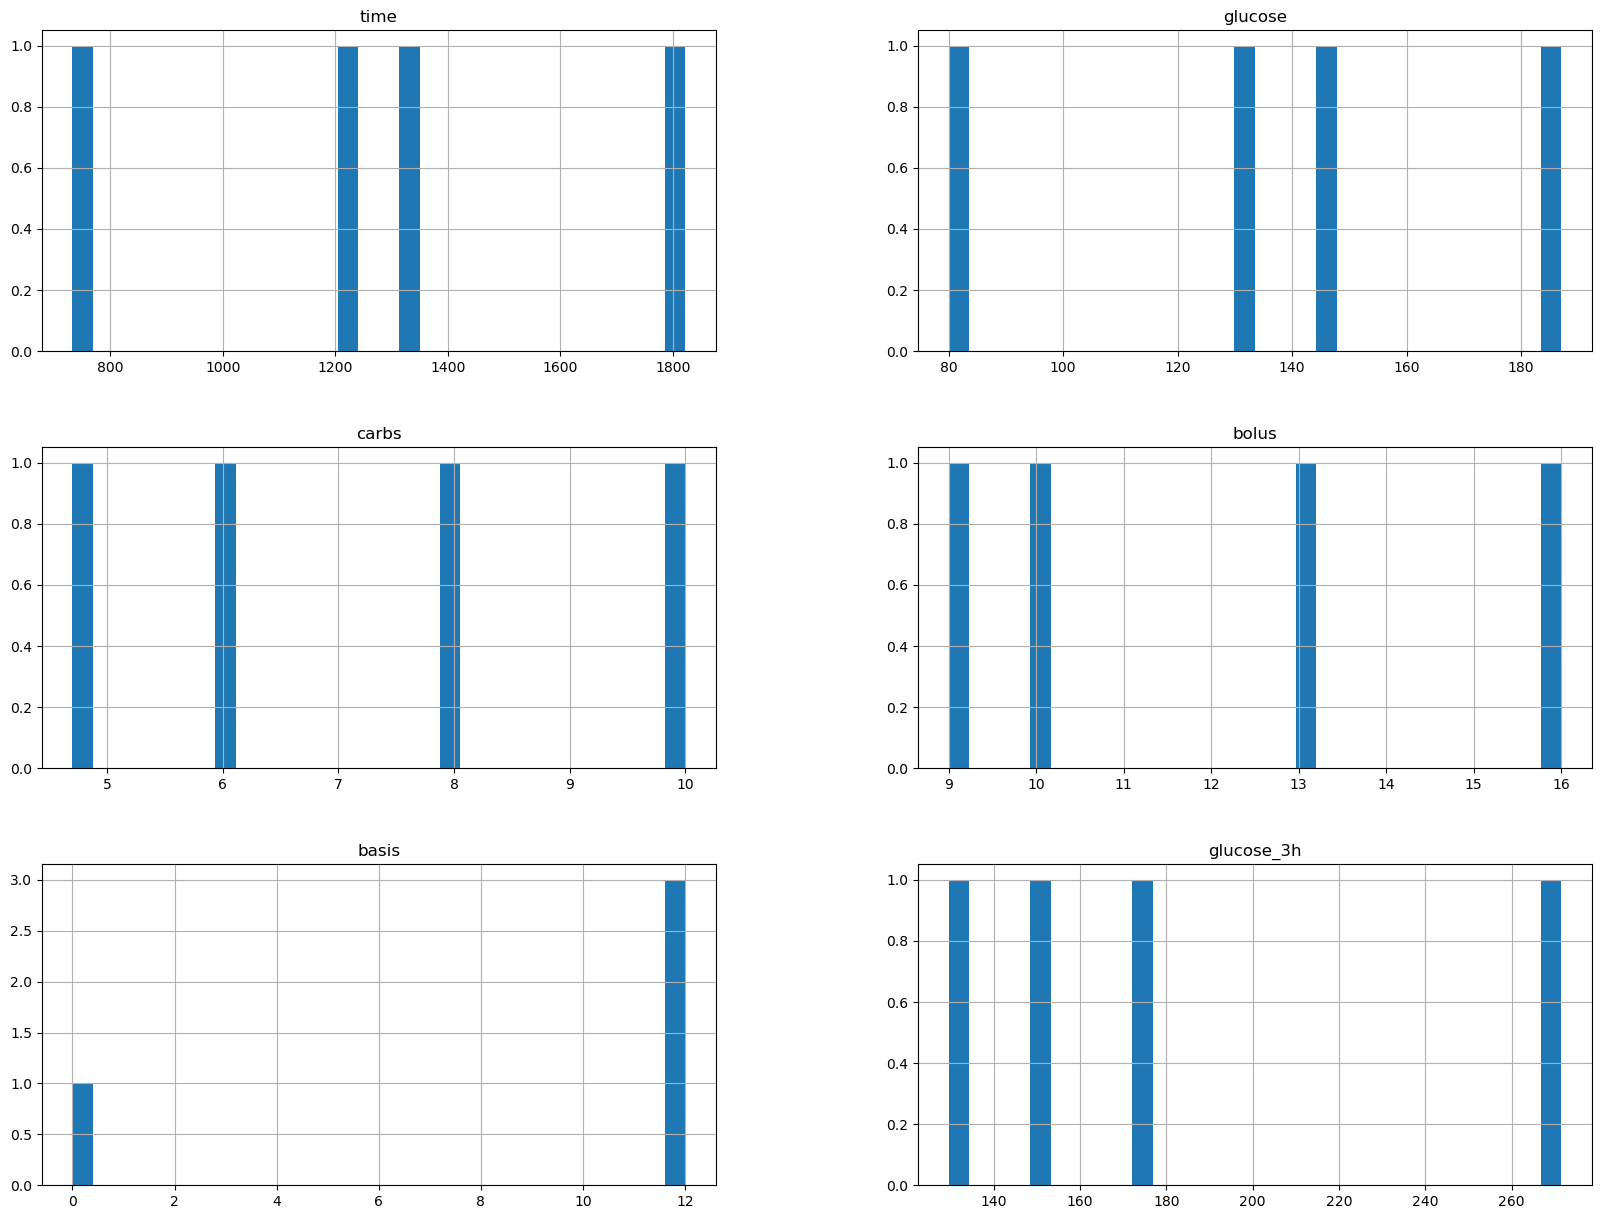



Plotting Time and glucose level after 3h as Ccatter Plot..


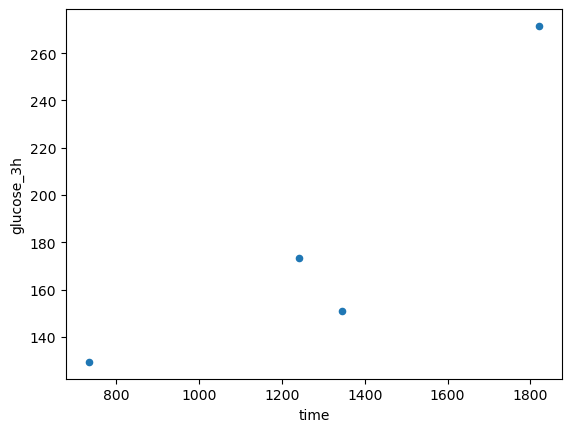



----- Correlation Matrix -----
glucose_3h    1.000000
time          0.899097
glucose       0.564110
basis         0.323195
bolus        -0.017986
carbs        -0.577330
Name: glucose_3h, dtype: float64


Plotting Correlations..


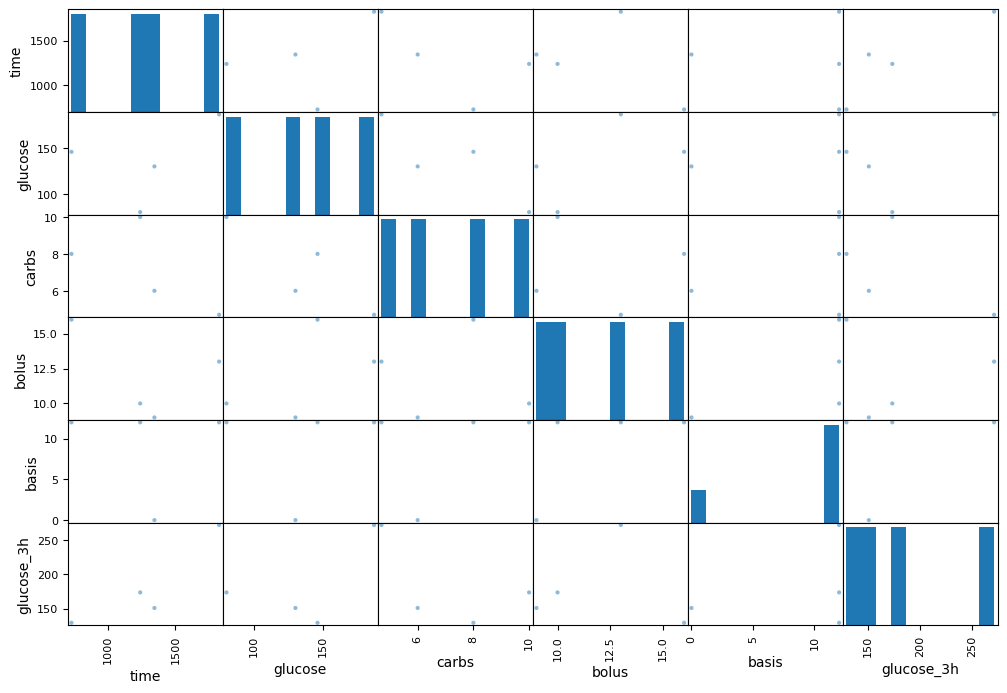

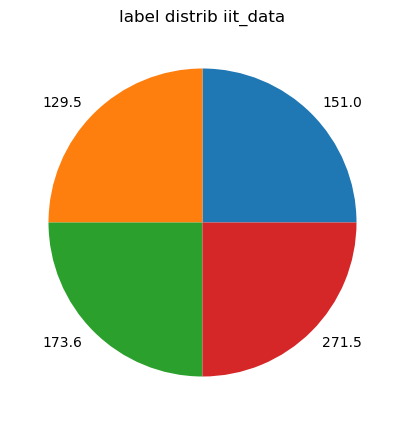

In [20]:
def analyze_data(iit_data):
    print("\n\n----- iit data head -----")
    print(iit_data.head())
    
    print("\n\n----- Data info -----")
    print(iit_data.info())

    print("\n\n----- Data Description -----")
    print(iit_data.describe())

    print("\nPlotting Features as Histograms..")
    iit_data.hist(bins=30, figsize=(20, 15))

    plt.show()

    print("\n\nPlotting Time and glucose level after 3h as Ccatter Plot..")
    iit_data.plot(kind="scatter", x="time", y="glucose_3h")

    plt.show()

    print("\n\n----- Correlation Matrix -----")
    corr_matrix = iit_data.corr()
    print(corr_matrix["glucose_3h"].sort_values(ascending=False))

    print("\n\nPlotting Correlations..")
    attributes = ["time", "glucose", "carbs", "bolus", "basis", "glucose_3h"]
    scatter_matrix(iit_data[attributes], figsize=(12, 8))

    plt.show()

    """\n\nPlotting Pie-Plot of labels.. """
    counts = iit_data['glucose_3h'].value_counts()
    counts.plot.pie(figsize=(5, 5))
    plt.title('label distrib iit_data')
    plt.ylabel('') 
    plt.show()

X_data = load_diary_data(diary_data_path)
gcm_data = load_gcm_data(gcm_data_path)

# add generated labels
y_data = gen_labels(X_data, gcm_data, 3)
X_data['glucose_3h'] = y_data

print("Visualizing iit data.. ")
analyze_data(pp_analysis(X_data))